In [57]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from statsmodels.tsa.statespace.sarimax import SARIMAXResults
from statsmodels.tsa.arima.model import ARIMAResults
from sklearn.preprocessing import MinMaxScaler
import sys
sys.path.append('../scripts') 
from Train_model import LSTMModel
import warnings
warnings.filterwarnings('ignore')

In [58]:
def load_data(file_path):
    """Load stock data from a CSV file."""
    data= pd.read_csv(file_path, parse_dates=["Date"], index_col="Date")
    data["Close"] = pd.to_numeric(data["Close"], errors="coerce")
    data = data.dropna(subset=["Close"])
    data = data[data.index >= '2015-01-01']
    return data


In [59]:
def load_models(model_paths):
    """Load ARIMA, SARIMA, and LSTM models."""
    arima_model = ARIMAResults.load(model_paths['arima'])
    sarima_model = SARIMAXResults.load(model_paths['sarima'])
    lstm_model = torch.load(model_paths['lstm'])
    lstm_model.eval()
    return arima_model, sarima_model, lstm_model


In [60]:
def forecast_arima(arima_model, data, steps=252):
    """Generate ARIMA forecast starting from filtered data."""
    arima_forecast = arima_model.get_forecast(steps=steps)
    predicted_mean = arima_forecast.predicted_mean
    conf_int = arima_forecast.conf_int()
    predicted_mean.index = pd.date_range(start=data.index[-1] + pd.Timedelta(days=1), periods=steps, freq="B")
    conf_int.index = predicted_mean.index
    return predicted_mean, conf_int





In [61]:
def forecast_sarima(sarima_model, data, steps=252):
    """Generate SARIMA forecast starting from filtered data."""
    sarima_forecast = sarima_model.get_forecast(steps=steps)
    predicted_mean = sarima_forecast.predicted_mean
    conf_int = sarima_forecast.conf_int()
    predicted_mean.index = pd.date_range(start=data.index[-1] + pd.Timedelta(days=1), periods=steps, freq="B")
    conf_int.index = predicted_mean.index
    return predicted_mean, conf_int

In [62]:
def forecast_lstm(lstm_model, data, steps, scaler, input_size):
    """
    Generate forecasts using the trained LSTM model.

    Parameters:
        lstm_model (torch.nn.Module): The trained LSTM model.
        data (np.ndarray): The historical data used for forecasting.
        steps (int): The number of future steps to forecast.
        scaler (MinMaxScaler): The scaler used during training.
        input_size (int): The number of features used in the LSTM model.

    Returns:
        np.ndarray: The forecasted values.
    """
    input_data = data[-input_size:].reshape(1, -1, input_size)  # Include all features
    lstm_forecast = []

    for _ in range(steps):
        # Predict the next step
        input_tensor = torch.tensor(input_data, dtype=torch.float32)
        pred = lstm_model(input_tensor).detach().numpy()

        # Extract the predicted value for the target variable
        next_day = pred[0, -1]
        lstm_forecast.append(next_day)

        # Expand the prediction to match the input feature size
        padded_pred = np.full((1, 1, input_size), next_day)

        # Update input_data with the padded prediction
        input_data = np.hstack((input_data[:, 1:, :], padded_pred))

    # Inverse scale the forecast
    lstm_forecast = scaler.inverse_transform(np.array(lstm_forecast).reshape(-1, 1))
    return lstm_forecast


In [63]:
def plot_forecast(data, forecast, confidence_interval=None, label="Forecast", color="blue"):
    """Plot historical data from 2015 with forecast and optional confidence interval."""
    plt.figure(figsize=(12, 6))
    plt.plot(data[data.index >= '2015-01-01'], label="Historical Data (From 2015)", color="black")
    plt.plot(forecast.index, forecast, label=label, color=color)
    if confidence_interval is not None:
        plt.fill_between(confidence_interval.index,
                         confidence_interval.iloc[:, 0],
                         confidence_interval.iloc[:, 1],
                         color=color, alpha=0.2, label="Confidence Interval")
    plt.title(f"{label} Forecast (From 2015)")
    plt.xlabel("Date")
    plt.ylabel("Price")
    plt.legend()
    plt.show()


In [64]:
def analyze_forecast(forecast, confidence_interval=None):
    """Analyze trends and risks in the forecast."""
    trend = "upward" if forecast.iloc[-1] > forecast.iloc[0] else "downward"
    print(f"Trend Analysis: Long-term trend appears to be {trend}")
    if confidence_interval is not None:
        volatility = confidence_interval.iloc[-1, 1] - confidence_interval.iloc[-1, 0]
        print(f"Volatility Analysis: Confidence Interval Width = {volatility}")


In [65]:
def forecast_market(data_path, model_paths, steps=252):
    """Forecast future stock prices for a given dataset."""
    # Load data and models
    data = load_data(data_path)
    arima_model, sarima_model, lstm_model = load_models(model_paths)
    # Filter data from 2015 onward
    data = data[data.index >= '2015-01-01']

    # ARIMA Forecast
    arima_pred, arima_conf_int = forecast_arima(arima_model, data, steps)
    plot_forecast(data["Close"], arima_pred, arima_conf_int, label="ARIMA", color="orange")
    analyze_forecast(arima_pred, arima_conf_int)
    # SARIMA Forecast
    sarima_pred, sarima_conf_int = forecast_sarima(sarima_model, data, steps)
    plot_forecast(data["Close"], sarima_pred, sarima_conf_int, label="SARIMA", color="green")
    analyze_forecast(sarima_pred, sarima_conf_int)
       

    # Forecast with LSTM
    scaler = MinMaxScaler()
    scaled_data = scaler.fit_transform(data[['Adj Close', 'Close', 'High', 'Low', 'Open', 'Volume', 'Daily Return']].values)
    input_size = scaled_data.shape[1]  # Dynamically determine the input size
    lstm_forecast = forecast_lstm(lstm_model, scaled_data, steps, scaler, input_size)

    forecast_dates = pd.date_range(data.index[-1] + pd.Timedelta(days=1), periods=steps, freq="B")
    lstm_forecast_series = pd.Series(lstm_forecast.flatten(), index=forecast_dates)
    plot_forecast(data["Close"], lstm_forecast_series, label="LSTM", color="purple")
    analyze_forecast(lstm_forecast_series)



Forecasting for Tesla


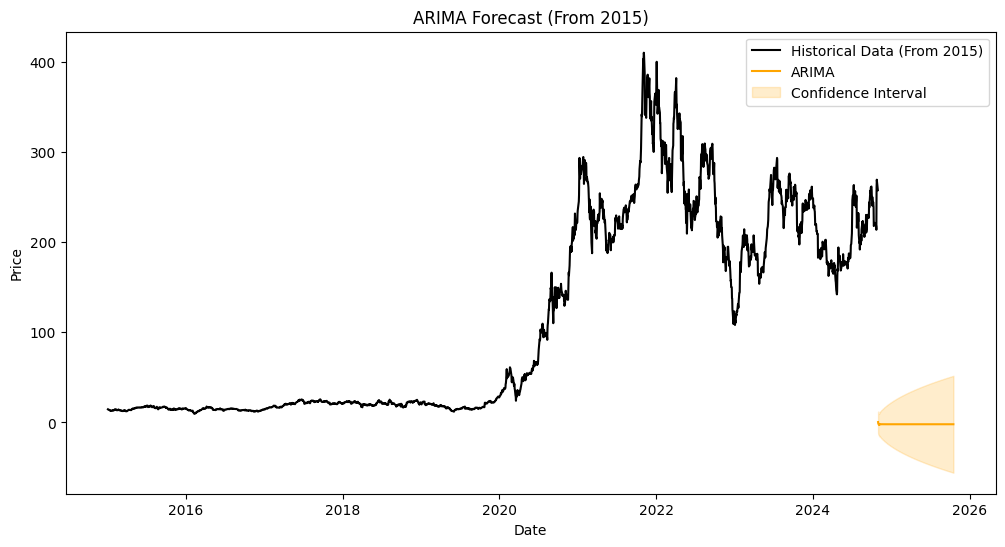

Trend Analysis: Long-term trend appears to be downward
Volatility Analysis: Confidence Interval Width = 107.4884881680596


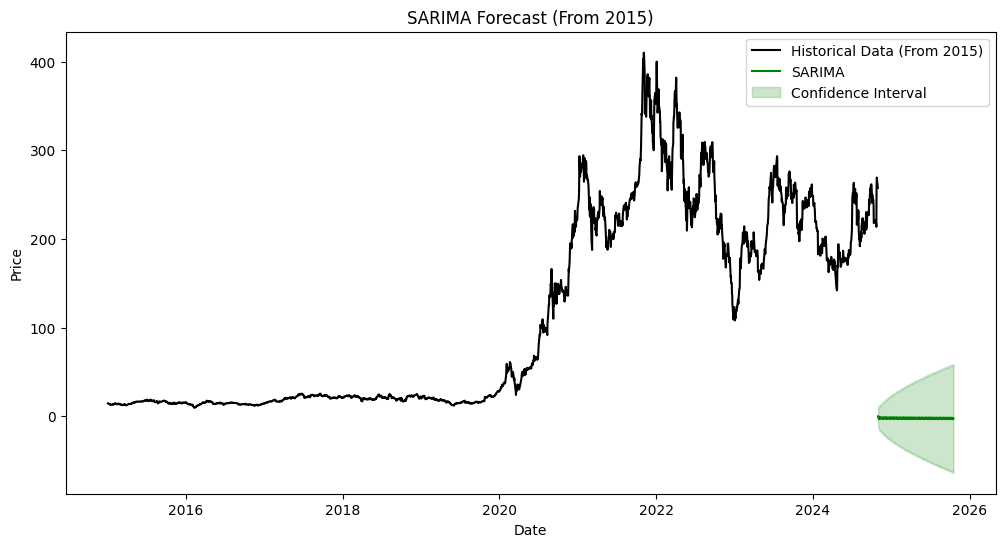

Trend Analysis: Long-term trend appears to be downward
Volatility Analysis: Confidence Interval Width = 121.6709757474705


ValueError: non-broadcastable output operand with shape (252,1) doesn't match the broadcast shape (252,7)

In [66]:
# File paths and model paths for Tesla
tesla_file_path = "../data/TSLA_proccessed_data.csv"
tesla_models = {
   "arima": "../models/TSLA_arima_model.pkl",
    "sarima": "../models/TSLA_sarima_model.pkl",
    "lstm": "../models/TSLA_lstm_model.pth"
}

# Forecast for Tesla
print("\nForecasting for Tesla")
forecast_market(tesla_file_path, tesla_models)



Forecasting for SPY


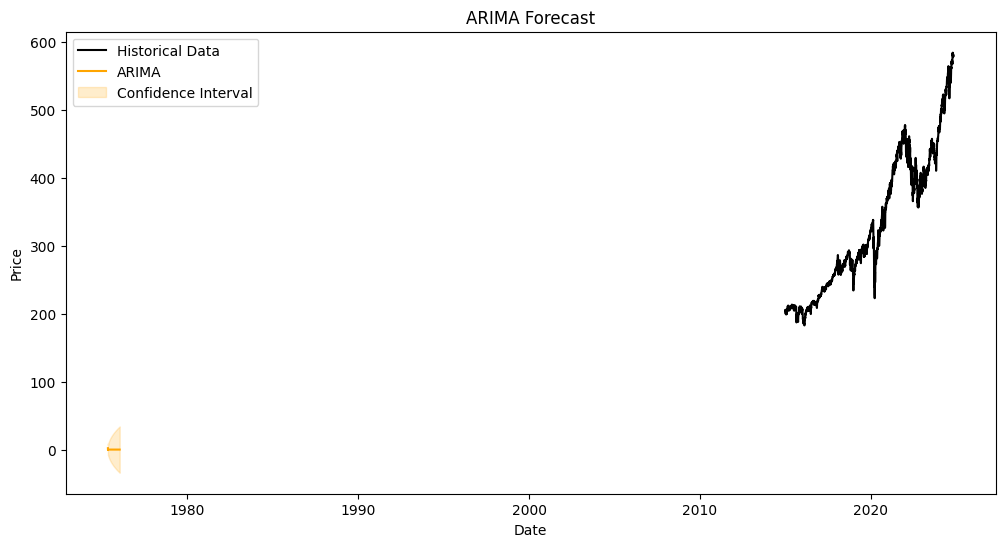

Trend Analysis: Long-term trend appears to be downward
Volatility Analysis: Confidence Interval Width = 68.19831216550762


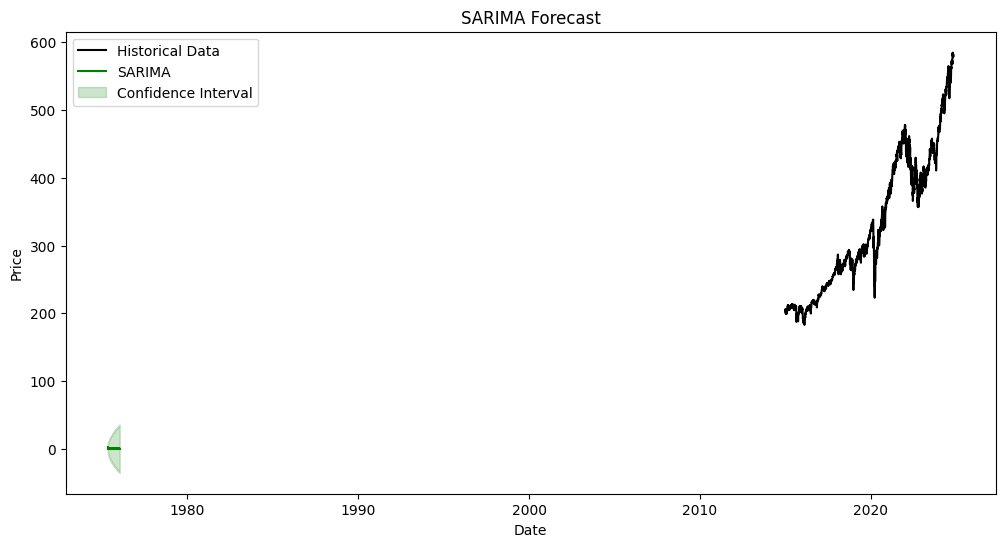

Trend Analysis: Long-term trend appears to be downward
Volatility Analysis: Confidence Interval Width = 70.46877794539672


AttributeError: 'LSTMModel' object has no attribute 'input_size'

In [ ]:
# File paths and model paths for SPY
spy_file_path ="../data/SPY_proccessed_data.csv"
spy_models = {
   "arima": "../models/SPY_arima_model.pkl",
    "sarima": "../models/SPY_sarima_model.pkl",
    "lstm": "../models/SPY_lstm_model.pth"
}

# Forecast for SPY
print("\nForecasting for SPY")
forecast_market(spy_file_path, spy_models)



Forecasting for BND


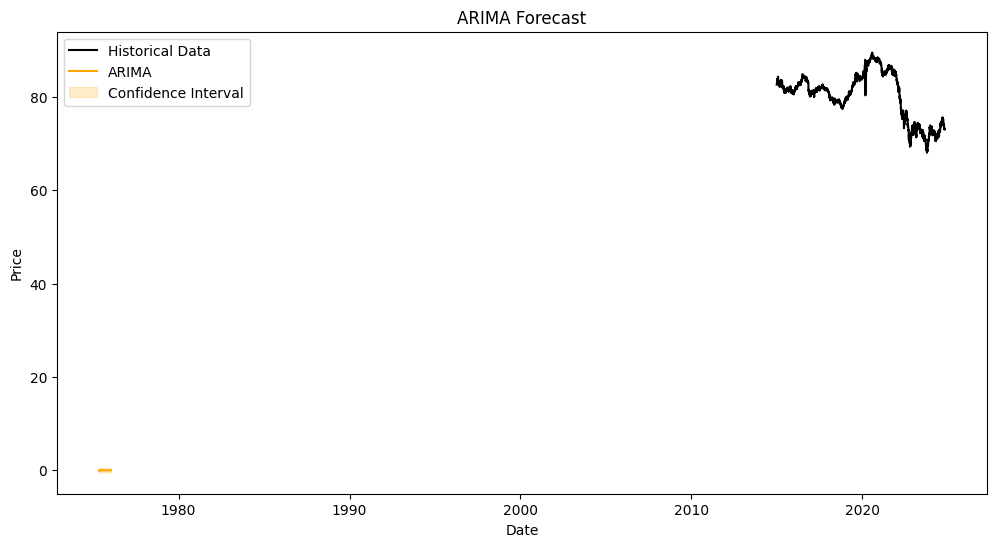

Trend Analysis: Long-term trend appears to be upward
Volatility Analysis: Confidence Interval Width = 0.911722975468812


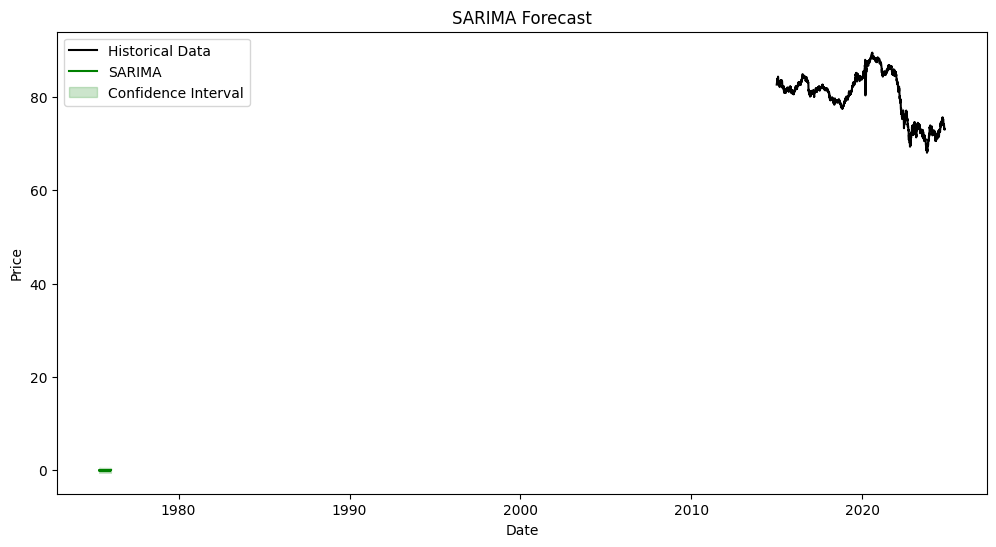

Trend Analysis: Long-term trend appears to be upward
Volatility Analysis: Confidence Interval Width = 0.9153508633244966


AttributeError: 'LSTMModel' object has no attribute 'input_size'

In [ ]:
# File paths and model paths for BND
bnd_file_path = "../data/BND_proccessed_data.csv"
bnd_models = {
    "arima": "../models/BND_arima_model.pkl",
    "sarima": "../models/BND_sarima_model.pkl",
    "lstm": "../models/BND_lstm_model.pth"
}

# Forecast for BND
print("\nForecasting for BND")
forecast_market(bnd_file_path, bnd_models)
